### Importing Relevant Packages

In [84]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import statsmodels.graphics.tsaplots as sgt 
import statsmodels.tsa.stattools as sts 
from statsmodels.tsa.seasonal import seasonal_decompose
import seaborn as sns
sns.set()

### Loading and Transforming the Data

In [85]:
raw_csv_data = pd.read_csv("Index2018.csv") 
df_comp=raw_csv_data.copy()
df_comp.date = pd.to_datetime(df_comp.date, dayfirst = True)
df_comp.set_index("date", inplace=True)
df_comp=df_comp.asfreq('b')
df_comp=df_comp.ffill()

### Removing Surplus Data

In [86]:
df_comp['market_value']=df_comp.spx

In [87]:
del df_comp['spx']
del df_comp['dax']
del df_comp['ftse']
del df_comp['nikkei']
size = int(len(df_comp)*0.8)

df = df_comp.iloc[:size].copy()
df_test = df_comp.iloc[size:].copy()

### White Noise

In [88]:
wn = np.random.normal(loc = df.market_value.mean(), scale = df.market_value.std(), size = len(df))

In [89]:
df['wn'] = wn

In [90]:
df.describe()

,market_value,wn
count,5021.000000,5021.000000
mean,1091.651926,1093.609198
std,292.559287,294.454849
min,438.920000,47.158686
25%,914.620000,900.316201
50%,1144.650000,1093.299565
75%,1316.280729,1290.233139
max,1570.252238,2058.976942


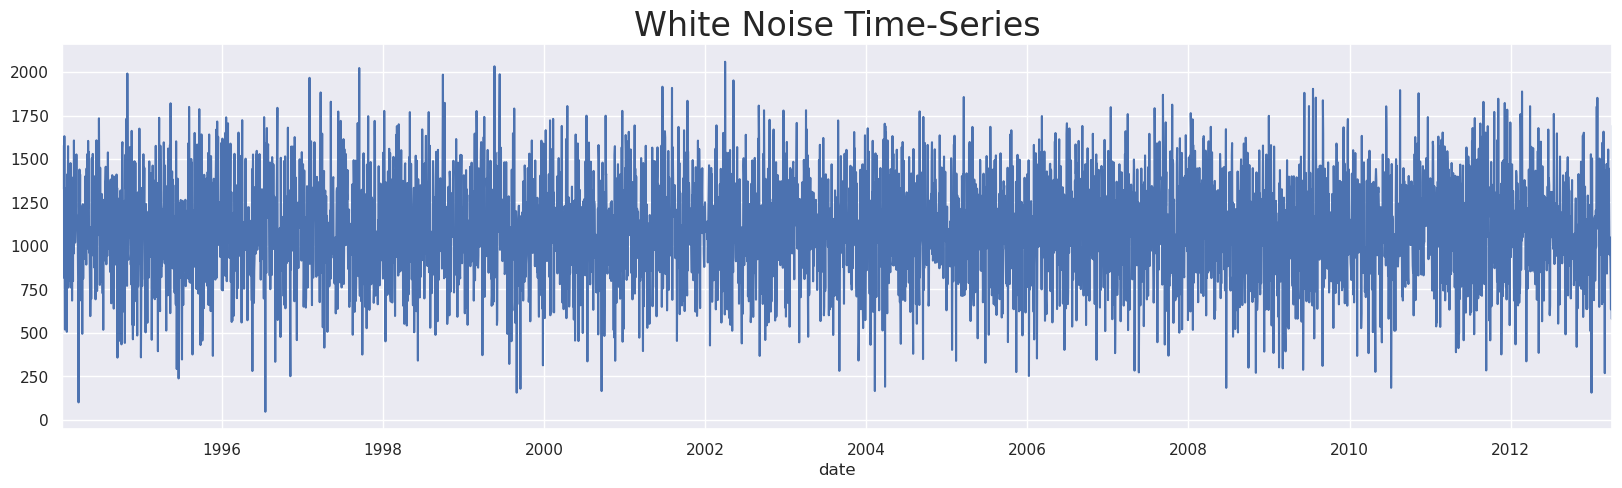

In [91]:
df.wn.plot(figsize = (20,5))
plt.title("White Noise Time-Series", size= 24)
plt.show()

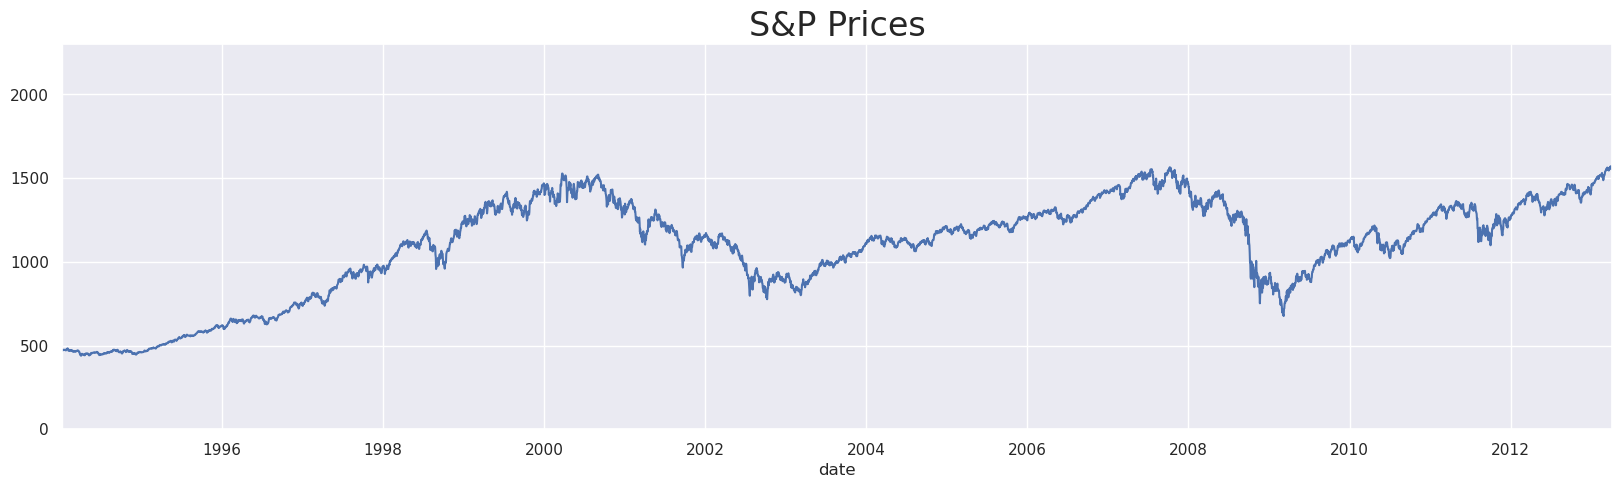

In [92]:
df.market_value.plot(figsize=(20,5))
plt.title("S&P Prices", size = 24)
plt.ylim(0,2300)
plt.show()

### Random Walk

In [93]:
rw = pd.read_csv("RandWalk.csv")
rw.date = pd.to_datetime(rw.date, dayfirst = True)
rw.set_index("date", inplace = True)
rw = rw.asfreq('b')

In [94]:
rw.describe()

,price
count,5021.000000
mean,1269.944293
std,444.216793
min,585.483034
25%,931.550429
50%,1156.363045
75%,1488.362029
max,2715.508720


In [95]:
df['rw'] = rw.price

In [96]:
df.head()

,market_value,wn,rw
date,,,
1994-01-07,469.90,1354.920703,1122.139662
1994-01-10,475.27,1573.328177,1080.347860
1994-01-11,474.13,1331.686379,1082.095245
1994-01-12,474.17,1539.007628,1083.639265
1994-01-13,472.47,1507.751588,1067.146255


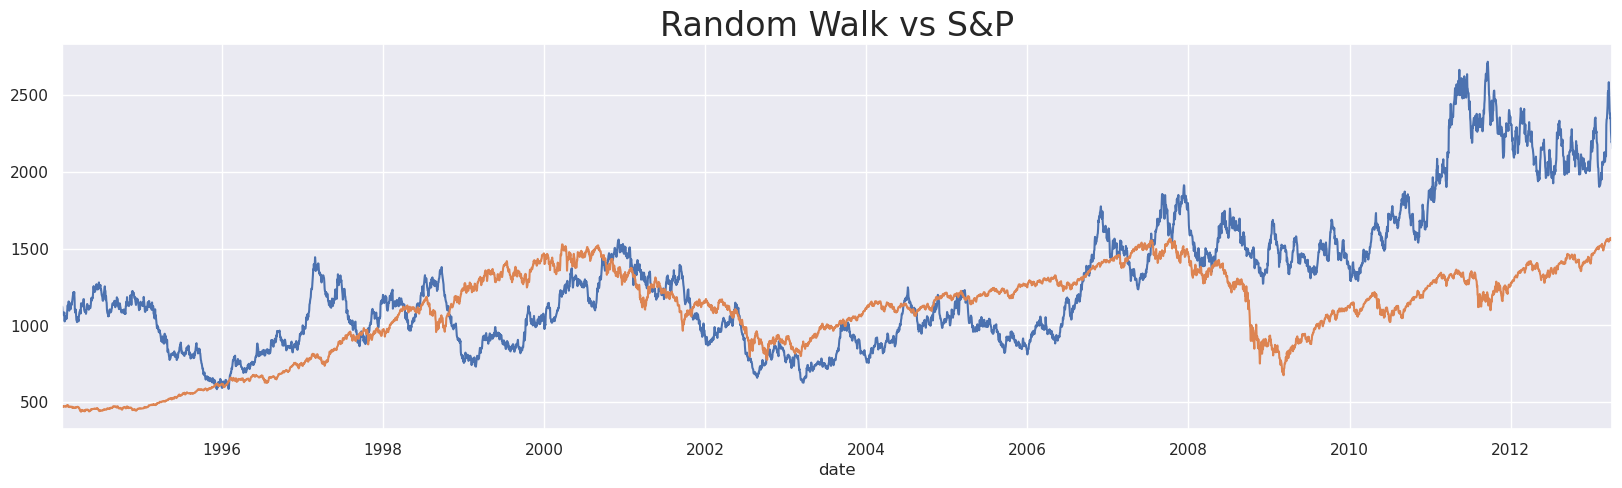

In [97]:
df.rw.plot(figsize = (20,5))
df.market_value.plot()
plt.title("Random Walk vs S&P", size = 24)
plt.show()

### Stationarity

In [98]:
sts.adfuller(df.market_value, result_object=True)

ADFullerResult
ADF Statistic: -1.73698
P-value: 0.41216
Used Lag: 18
Nobs: 5002
Critical Values: {'1%': np.float64(-3.431658008603046), '5%': np.float64(-2.862117998412982), '10%': np.float64(-2.567077669247375)}

In [99]:
sts.adfuller(df.wn, result_object=True)

ADFullerResult
ADF Statistic: -71.32551
P-value: 0.00000
Used Lag: 0
Nobs: 5020
Critical Values: {'1%': np.float64(-3.431653316130827), '5%': np.float64(-2.8621159253018247), '10%': np.float64(-2.5670765656497516)}

In [100]:
sts.adfuller(df.rw, result_object=True)

ADFullerResult
ADF Statistic: -1.32861
P-value: 0.61598
Used Lag: 24
Nobs: 4996
Critical Values: {'1%': np.float64(-3.4316595802782865), '5%': np.float64(-2.8621186927706463), '10%': np.float64(-2.567078038881065)}

### Seasonality

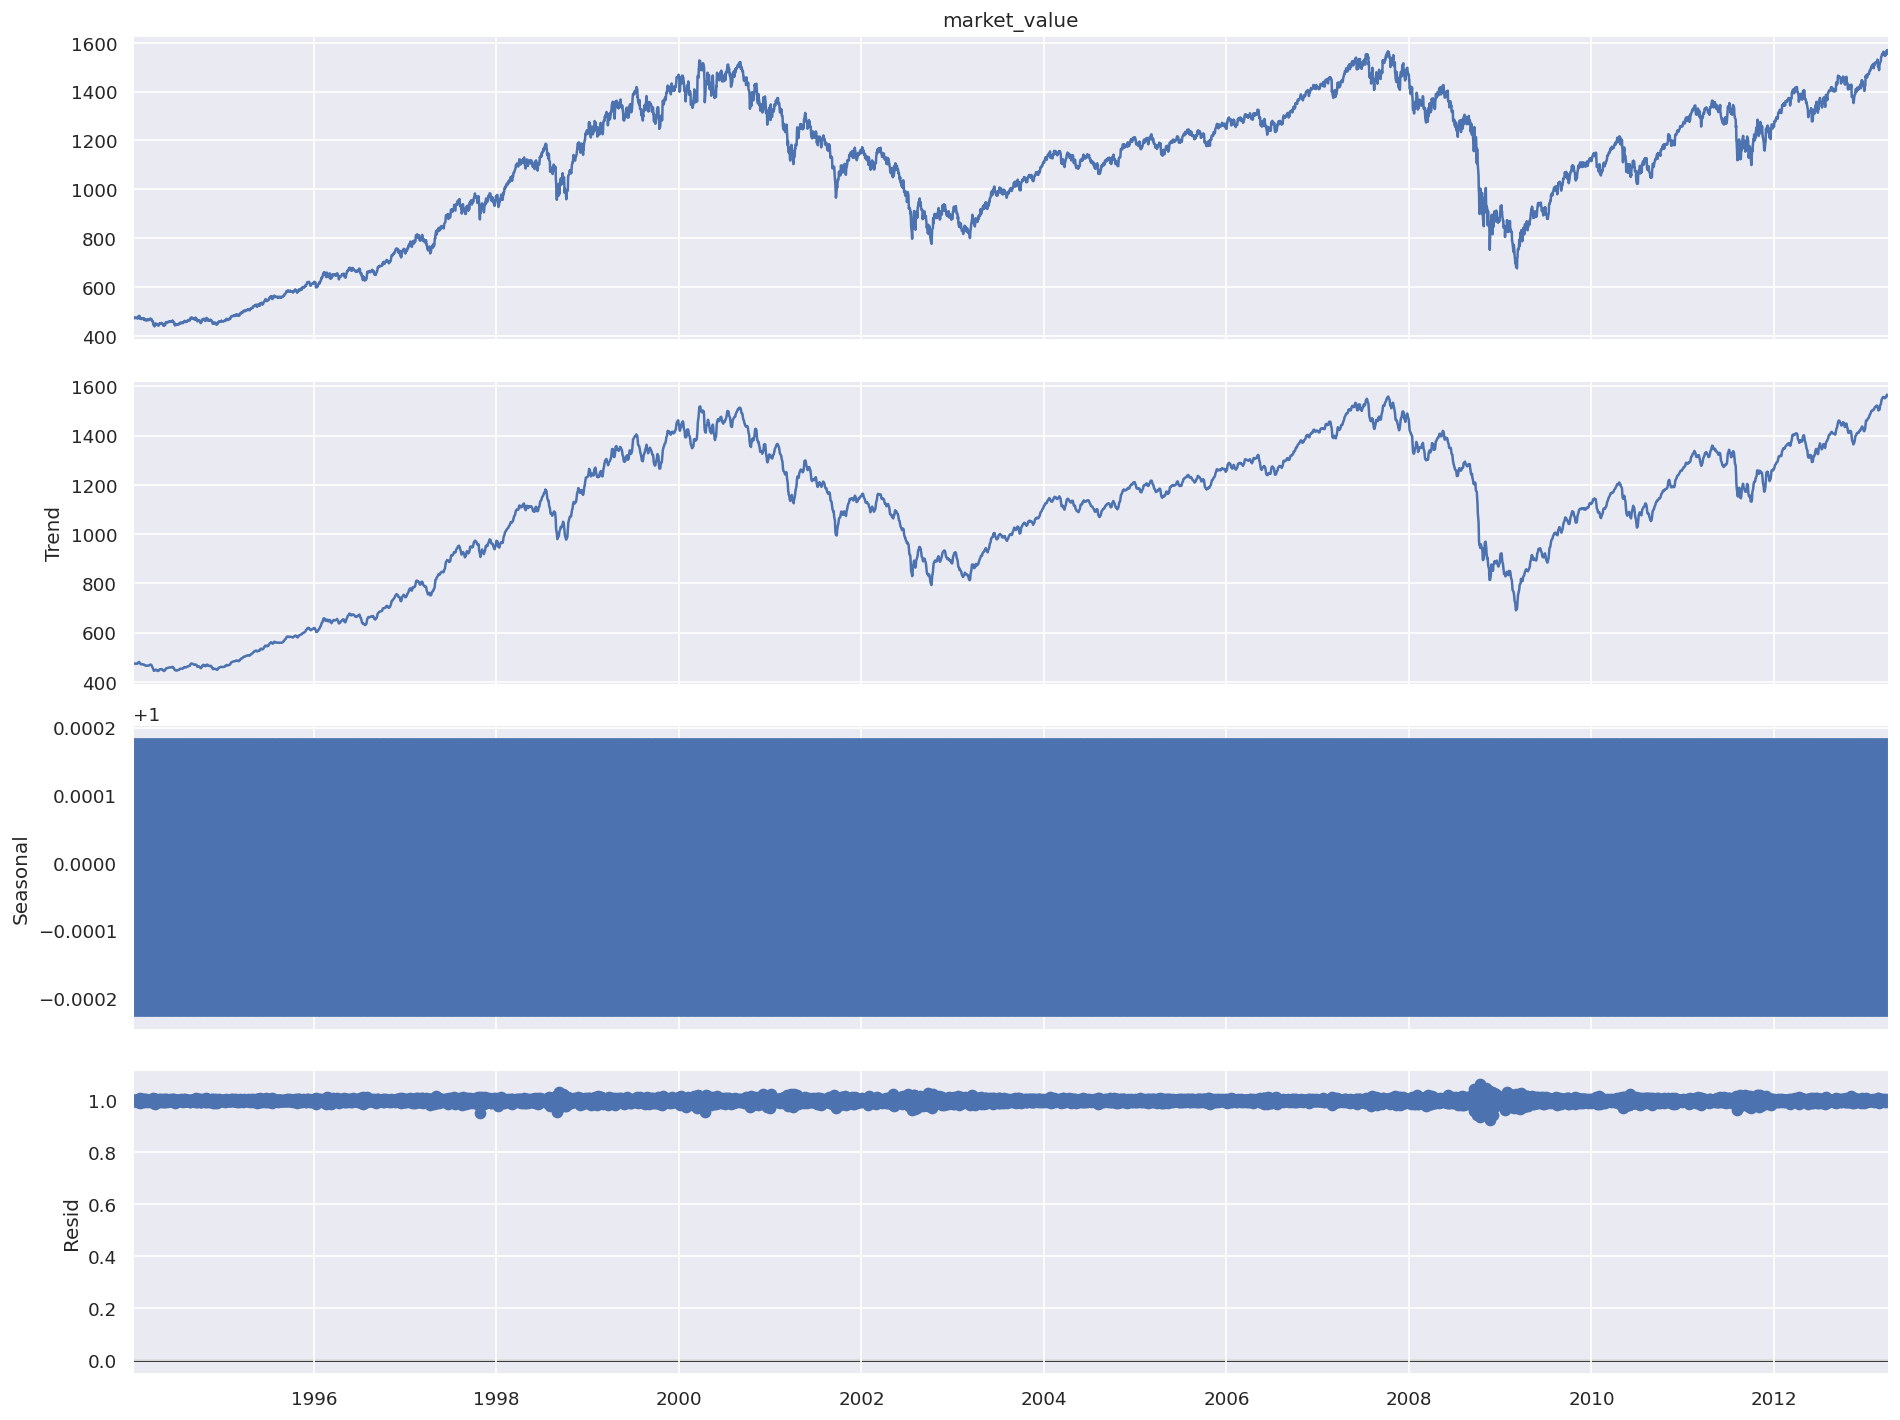

In [101]:
s_dec_multiplicative = seasonal_decompose(df.market_value, model="multiplicative")

fig = s_dec_multiplicative.plot()
fig.set_size_inches(16, 12)
fig.set_dpi(120)

plt.tight_layout()
plt.show()

### ACF

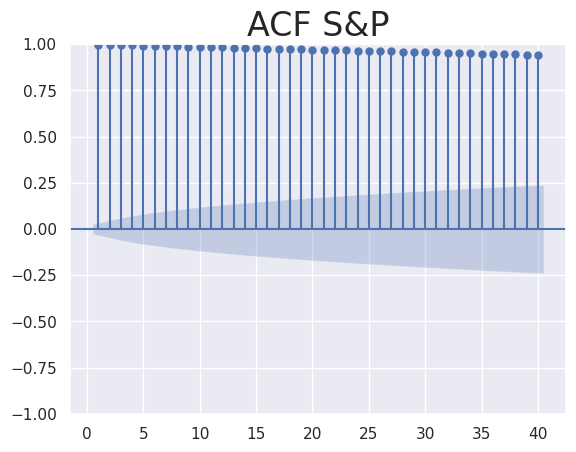

In [102]:
sgt.plot_acf(df.market_value, lags = 40, zero = False)
plt.title("ACF S&P", size = 24)
plt.show()

### PACF

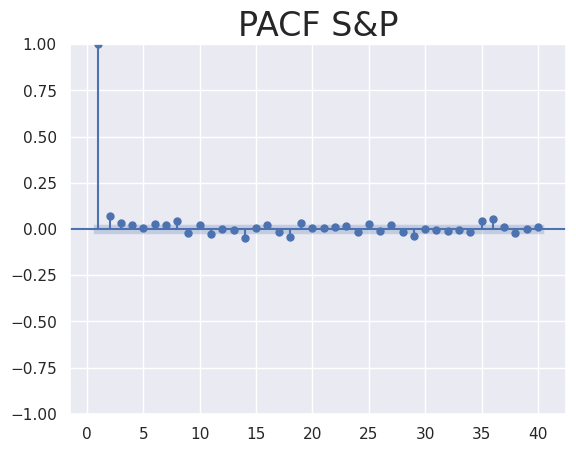

In [103]:
sgt.plot_pacf(df.market_value, lags = 40, zero = False, method = ('ols'))
plt.title("PACF S&P", size = 24)
plt.show()

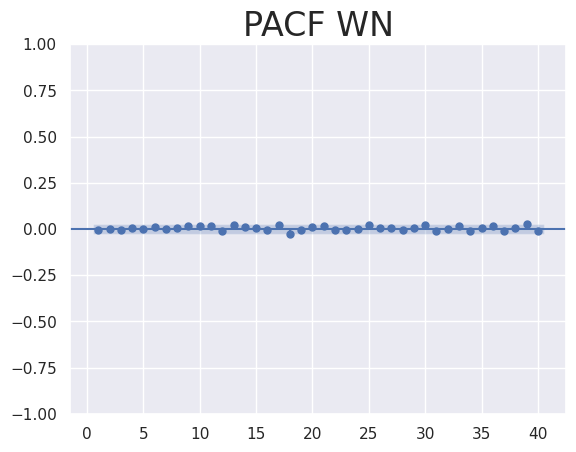

In [104]:
sgt.plot_pacf(df.wn, lags = 40, zero = False, method = ('ols'))
plt.title("PACF WN", size = 24)
plt.show()